# What lazy imports are for

PEP 810 did not claim that using a module gets cheaper. It lets you leave imports at the top of a file and load a module only if that run actually touches it. Startup gets faster, and the process stays smaller, on the commands that do not need the whole toolkit.

A comparison of one module that is always used hides that. Both styles then do the same work. This notebook times a small program that always *lists* the same imports, then runs one of four commands:

- `--help` touches none of them
- `csv dialects` touches `csv`
- `read extract` parses `data/California.csv`
- `load matplotlib` imports `matplotlib`

The import block is `asyncio`, `csv`, `ssl`, `urllib.request`, `numpy`, `matplotlib`, and the California extract. The eager program loads all of them before it looks at the command. The lazy program loads one only when the command uses that name.

## Run the trials

Run this notebook from `lazy-imports/` on Python 3.15 or newer, with `numpy` and `matplotlib` installed. The first trial of each command is discarded so the page cache is warm.

In [1]:
import json
import statistics
import subprocess
import sys
import time
from pathlib import Path

if sys.version_info < (3, 15):
    raise RuntimeError(
        "Python 3.15 or newer is required for the lazy keyword. "
        f"This kernel is {sys.version.split()[0]}."
    )

BENCH = Path("bench")
if not (BENCH / "eager_app.py").is_file():
    raise FileNotFoundError("Run this notebook from the lazy-imports directory.")

WARMUP = 1
TRIALS = 9
COMMANDS = ("help", "csv", "records", "plot")
STYLES = ("eager", "lazy")


def run_once(style: str, command: str) -> dict:
    started = time.perf_counter()
    proc = subprocess.run(
        [sys.executable, str(BENCH / f"{style}_app.py"), command],
        check=True,
        capture_output=True,
        text=True,
    )
    record = json.loads(proc.stdout)
    record["command"] = command
    record["wall_ms"] = (time.perf_counter() - started) * 1000
    return record


trials = []
for command in COMMANDS:
    for style in STYLES:
        for index in range(WARMUP + TRIALS):
            record = run_once(style, command)
            if index >= WARMUP:
                trials.append(record)

print(f"{len(trials)} trials on Python {sys.version.split()[0]}")

72 trials on Python 3.15.0rc2


## Chart

Time is measured inside the process, from the import block through the command. Peak resident memory is the process high-water mark. The eager bars should sit near each other: every command loaded the whole toolkit. The lazy bars should follow what that command touched.

command              eager ms    lazy ms   eager MB    lazy MB
--------------------------------------------------------------
--help                  200.3        0.0       65.8       19.8
csv dialects            204.7        0.8       65.8       19.9
read extract            204.1       24.8       65.8       27.8
load matplotlib         202.1      155.5       65.7       52.7


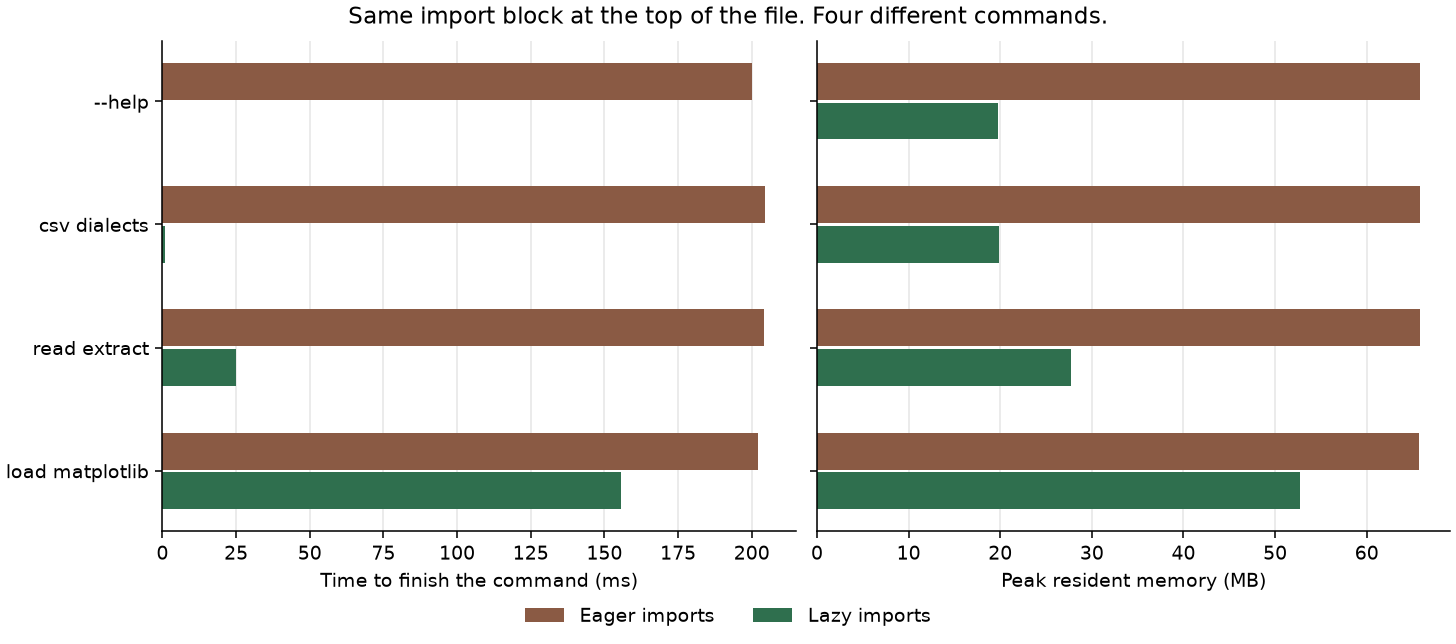

In [2]:
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

LABEL = {
    "help": "--help",
    "csv": "csv dialects",
    "records": "read extract",
    "plot": "load matplotlib",
}
COLORS = {"eager": "#8a5a44", "lazy": "#2f6f4e"}


def values(style: str, command: str, key: str) -> list[float]:
    return [
        row[key]
        for row in trials
        if row["style"] == style and row["command"] == command
    ]


def median(style: str, command: str, key: str) -> float:
    return statistics.median(values(style, command, key))


def show_table() -> None:
    header = f"{'command':<18} {'eager ms':>10} {'lazy ms':>10} {'eager MB':>10} {'lazy MB':>10}"
    print(header)
    print("-" * len(header))
    for command in COMMANDS:
        print(
            f"{LABEL[command]:<18} "
            f"{median('eager', command, 'total_ms'):10.1f} "
            f"{median('lazy', command, 'total_ms'):10.1f} "
            f"{median('eager', command, 'rss_bytes') / 1e6:10.1f} "
            f"{median('lazy', command, 'rss_bytes') / 1e6:10.1f}"
        )


def draw(path: Path) -> None:
    fig, axes = plt.subplots(
        1, 2, figsize=(10.4, 4.6), sharey=True, constrained_layout=True
    )
    panels = (
        ("total_ms", 1, "Time to finish the command (ms)"),
        ("rss_bytes", 1e6, "Peak resident memory (MB)"),
    )
    positions = list(range(len(COMMANDS) - 1, -1, -1))
    for ax, (key, scale, xlabel) in zip(axes, panels):
        for offset, style in ((0.16, "eager"), (-0.16, "lazy")):
            heights = [median(style, command, key) / scale for command in COMMANDS]
            ax.barh(
                [pos + offset for pos in positions],
                heights,
                height=0.3,
                color=COLORS[style],
                label="Eager imports" if style == "eager" else "Lazy imports",
                zorder=2,
            )
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", color="#e6e6e6", zorder=0)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    axes[0].set_yticks(positions, [LABEL[command] for command in COMMANDS])
    fig.legend(
        handles=axes[0].containers,
        labels=["Eager imports", "Lazy imports"],
        loc="outside lower center",
        ncol=2,
        frameon=False,
    )
    fig.suptitle("Same import block at the top of the file. Four different commands.")
    fig.savefig(path, dpi=140)
    plt.close(fig)


show_table()
figure_path = Path("import_cost.png")
draw(figure_path)
display(Image(filename=str(figure_path)))

## Conclusion

The run counts when the eager commands stay within 15% of each other, `--help` is slower and larger when the imports are eager, and the lazy `load matplotlib` command is still lighter than the eager one because the other modules stayed unloaded. The two `read extract` commands also have to return the same summary.

In [3]:
def quartile(sample: list[float], which: int) -> float:
    return statistics.quantiles(sample, n=4)[which]


def separated(command: str, key: str) -> bool:
    lazy = values("lazy", command, key)
    eager = values("eager", command, key)
    return quartile(lazy, 2) < quartile(eager, 0)


eager_help = median("eager", "help", "total_ms")
eager_flat = all(
    abs(median("eager", command, "total_ms") - eager_help) / eager_help < 0.15
    for command in COMMANDS
)
help_faster = separated("help", "total_ms") and separated("help", "rss_bytes")
plot_lighter = (
    median("lazy", "plot", "total_ms") < median("eager", "plot", "total_ms")
    and median("lazy", "plot", "rss_bytes") < median("eager", "plot", "rss_bytes")
)
records = [
    row["answer"]
    for row in trials
    if row["command"] == "records"
]
same_records = all(answer == records[0] for answer in records)
cleared = eager_flat and help_faster and plot_lighter and same_records

if cleared:
    summary = records[0]
    print(
        f"Every eager command took about {eager_help:.0f} ms and "
        f"{median('eager', 'help', 'rss_bytes') / 1e6:.0f} MB, "
        "because the toolkit loaded before the command ran. "
        f"Lazy --help took {median('lazy', 'help', 'total_ms'):.1f} ms and "
        f"{median('lazy', 'help', 'rss_bytes') / 1e6:.0f} MB. "
        f"Lazy read-extract took {median('lazy', 'records', 'total_ms'):.0f} ms "
        f"and {median('lazy', 'records', 'rss_bytes') / 1e6:.0f} MB. "
        f"Lazy matplotlib took {median('lazy', 'plot', 'total_ms'):.0f} ms "
        f"and {median('lazy', 'plot', 'rss_bytes') / 1e6:.0f} MB, "
        "against "
        f"{median('eager', 'plot', 'total_ms'):.0f} ms and "
        f"{median('eager', 'plot', 'rss_bytes') / 1e6:.0f} MB eager, "
        "because the extract, urllib, and asyncio stayed unloaded. "
        f"Both extract reads agreed: {summary['rows']} rows, "
        f"{summary['same_state_rate']:.1%} with matching state labels. "
        "That share describes this Wikidata extract, not California residents."
    )
else:
    print(
        "This run did not clear the bar.",
        f"eager_flat={eager_flat}",
        f"help_faster={help_faster}",
        f"plot_lighter={plot_lighter}",
        f"same_records={same_records}",
    )

Every eager command took about 200 ms and 66 MB, because the toolkit loaded before the command ran. Lazy --help took 0.0 ms and 20 MB. Lazy read-extract took 25 ms and 28 MB. Lazy matplotlib took 156 ms and 53 MB, against 202 ms and 66 MB eager, because the extract, urllib, and asyncio stayed unloaded. Both extract reads agreed: 4886 rows, 59.6% with matching state labels. That share describes this Wikidata extract, not California residents.
